In [52]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datetime import datetime

In [53]:
df = pd.read_csv(r"D:\python project\Pharmacy_Sales_Big_Raw.csv", encoding = 'unicode escape', low_memory=False)

In [54]:
df.shape

(56363, 34)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56363 entries, 0 to 56362
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Invoice_No        56323 non-null  object
 1   Store_ID          56318 non-null  object
 2   Store_Name        56318 non-null  object
 3   City              56318 non-null  object
 4   State             56318 non-null  object
 5   Pincode           56318 non-null  object
 6   Sale_Date         55186 non-null  object
 7   Sale_Time         50697 non-null  object
 8   Drug_Code         56318 non-null  object
 9   Drug_Name         56318 non-null  object
 10  Salt_Composition  56318 non-null  object
 11  Category          53987 non-null  object
 12  Manufacturer      56318 non-null  object
 13  Batch_No          51869 non-null  object
 14  Mfg_Date          50734 non-null  object
 15  Expiry_Date       52910 non-null  object
 16  HSN_Code          37310 non-null  object
 17  GST_Percent 

## ---> Start Data Cleaning

In [56]:
df.isnull().sum()

Invoice_No             40
Store_ID               45
Store_Name             45
City                   45
State                  45
Pincode                45
Sale_Date            1177
Sale_Time            5666
Drug_Code              45
Drug_Name              45
Salt_Composition       45
Category             2376
Manufacturer           45
Batch_No             4494
Mfg_Date             5629
Expiry_Date          3453
HSN_Code            19053
GST_Percent          7003
MRP                  5726
Selling_Price        5731
Quantity             3847
Unit                 8121
Discount_Percent     5689
Total_Amount         2206
Payment_Mode         5665
Customer_ID          8483
Customer_Age         8839
Customer_Gender      6933
Doctor_Name         21204
Prescription_No     42153
Stock_Before           45
Stock_After            45
Sales_Rep           14104
Remarks             10327
dtype: int64

In [57]:
int_null_columns = ['Quantity','MRP','Selling_Price','Discount_Percent','Total_Amount',
            'GST_Percent','Customer_Age','Stock_Before','Stock_After','HSN_Code']
ID_null_columns = ['Pincode','Customer_ID','Prescription_No','Drug_Code','Store_ID','Invoice_No','Batch_No']
Str_null_columns = ['Store_Name','City','State','Drug_Name','Salt_Composition','Category',
            'Manufacturer','Unit','Payment_Mode','Customer_Gender','Doctor_Name','Sales_Rep','Remarks']
Date_null_columns = ['Sale_Date','Mfg_Date','Expiry_Date']

In [58]:
junk_cols = [c for c in df.columns if 'Unnamed:' in str(c) or isinstance(c, tuple) or 'Discount_Percent,' in str(c)]
df.drop(columns= junk_cols, inplace= True, errors= 'ignore')

df.dropna(how= 'all', inplace= True)
df.drop(['Sale_Time'], axis=1, inplace= True)

In [59]:
if len(df) >0:
    header_mask = df.apply(lambda a: sum(str(a[c]) == str(c) for c in df.columns)/ len(df.columns) >=0.8, axis=1)
    df = df[~header_mask]

In [60]:
for c in int_null_columns:
    df[c]= pd.to_numeric(df[c].astype(str).str.replace(r'[%₹,]|Rs\.|INR', '', regex=True). str.strip(), errors='coerce')
df.loc[df['Quantity']<=0, 'Quantity']= np.nan
df.loc[~df['Customer_Age'].between(0,110), 'Customer_Age'] = np.nan
df[int_null_columns] = df[int_null_columns].fillna(df[int_null_columns].median())

In [61]:
for c in Str_null_columns:
    df[c] = df[c].astype(str).str.strip().replace({'nan' :np.nan, 'None': np.nan, 'NA': np.nan, '': np.nan})
    df[c] = df[c].fillna(df[c].mode()[0])if df [c].notna().any() else df[c]
df[['City','Manufacturer','Payment_Mode']] = df[['City','Manufacturer','Payment_Mode']].apply(lambda s:s.str.title())
df['Customer_Gender'] = df['Customer_Gender'].replace({'M':'Male', 'F': 'Female', 'm':'Male', 'f':'Female'})

In [62]:
for c in Date_null_columns:
    result,remaining = pd.Series(pd.NaT, index=df.index), df[c].copy()
    for fmt in ['%d-%m-%Y', '%d/%m/%Y', '%Y-%m-%d', '%y-%m-%d', '%y/%m/%d', '%m/%d/%Y']:
        parsed = pd.to_datetime(remaining,format=fmt, errors= 'coerce')
        result, remaining =result.fillna(parsed), remaining.where(parsed.isna())
    df[c]= result.fillna(pd.to_datetime(remaining, errors='coerce', dayfirst=True))
df.drop_duplicates(inplace=True)

In [63]:
df['Is_Stockout'] = df['Stock_After'] < 0
df['Stockout_Deficit'] = np.where(df['Stock_After'] < 0, df['Stock_After'].abs(), 0)
df['Stock_After'] = df['Stock_After'].clip(lower=0)

df['Order_Type'] = np.where(df['Quantity'] >= 20, 'Bulk Order', 'Retail')

df['Gross_Revenue'] = df['Quantity'] * df['Selling_Price']
df['Discount_Amount'] = df['Quantity'] * (df['MRP'] - df['Selling_Price'])

age_bins = [0, 18, 35, 50, 65, 100]
age_labels = ['Under 18', '19-35', '36-50', '51-65', '65+']
df['Age_Group'] = pd.cut(df['Customer_Age'], bins=age_bins, labels=age_labels)

In [64]:
df.isna().sum()

Invoice_No              0
Store_ID                1
Store_Name              0
City                    0
State                   0
Pincode                 1
Sale_Date            1110
Drug_Code               1
Drug_Name               0
Salt_Composition        0
Category                0
Manufacturer            0
Batch_No             4335
Mfg_Date             5459
Expiry_Date          3318
HSN_Code                0
GST_Percent             0
MRP                     0
Selling_Price           0
Quantity                0
Unit                    0
Discount_Percent        0
Total_Amount            0
Payment_Mode            0
Customer_ID          8194
Customer_Age            0
Customer_Gender         0
Doctor_Name             0
Prescription_No     41064
Stock_Before            0
Stock_After             0
Sales_Rep               0
Remarks                 0
Is_Stockout             0
Stockout_Deficit        0
Order_Type              0
Gross_Revenue           0
Discount_Amount         0
Age_Group   

In [65]:
df['Batch_No'] = df['Batch_No'].fillna('Unknown')
df['Customer_ID'] = df['Customer_ID'].fillna('Not Provided')
df['Prescription_No'] = df['Prescription_No'].fillna('Unknown')

In [66]:
df[ ['Quantity','MRP','Selling_Price','Discount_Percent','Total_Amount',
            'GST_Percent','Customer_Age','Stock_Before','Stock_After']].describe()

,Quantity,MRP,Selling_Price,Discount_Percent,Total_Amount,GST_Percent,Customer_Age,Stock_Before,Stock_After
count,54961.000000,54961.000000,54961.000000,54961.000000,54961.000000,54961.000000,54961.000000,54961.000000,54961.000000
mean,14.072360,74.152668,68.751899,6.948018,924.527511,10.121595,45.675461,248.869990,236.718528
std,36.327889,65.219883,60.329088,7.150723,3395.186076,4.412476,21.568438,144.784174,146.291738
min,1.000000,12.000000,10.000000,0.000000,10.230000,5.000000,1.000000,0.000000,0.000000
25%,2.000000,34.500000,31.880000,0.000000,58.070000,5.000000,33.000000,123.000000,109.000000
50%,3.000000,53.720000,50.000000,5.000000,125.630000,12.000000,46.000000,247.000000,234.000000
75%,6.000000,97.140000,90.000000,15.000000,357.570000,12.000000,58.000000,375.000000,362.000000
max,150.000000,416.000000,414.000000,20.000000,59698.070000,18.000000,90.000000,500.000000,499.000000


## ---> Let's Build Visuals

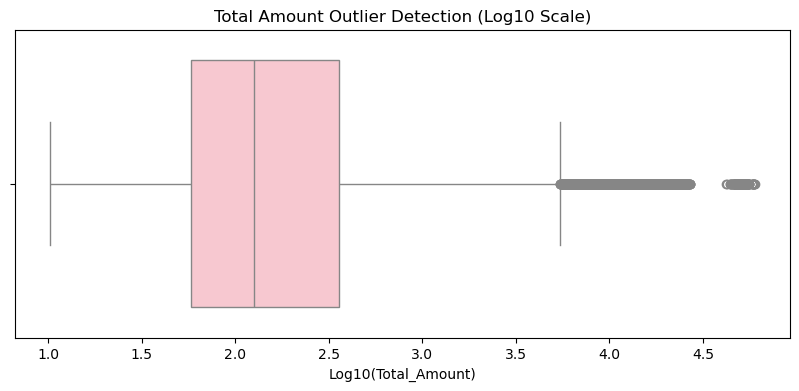

In [67]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=np.log10(df["Total_Amount"].replace(0, np.nan)), color="pink")
plt.title("Total Amount Outlier Detection (Log10 Scale)")
plt.xlabel("Log10(Total_Amount)")
plt.show()

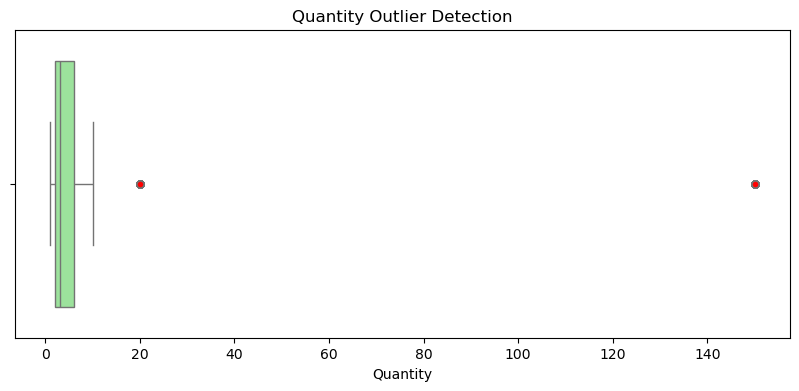

In [68]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Quantity"], color="lightgreen", flierprops={"markerfacecolor": "red", "markersize": 5})
plt.title("Quantity Outlier Detection")
plt.xlabel("Quantity")
plt.show()

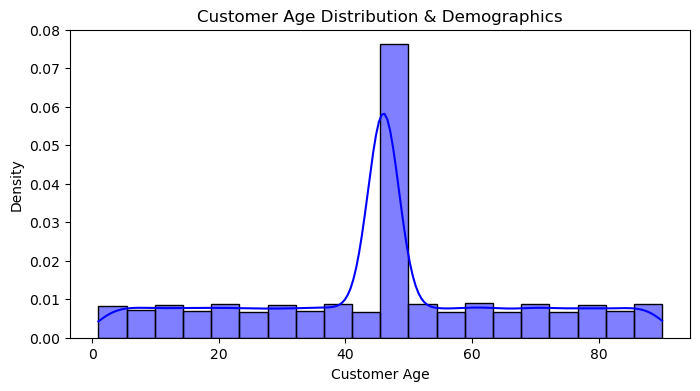

In [69]:
plt.figure(figsize= (8,4))
sns.histplot(df['Customer_Age'], kde=True, bins=20, color='blue', stat='density')

plt.title('Customer Age Distribution & Demographics')
plt.xlabel('Customer Age')
plt.ylabel('Density')
plt.show()

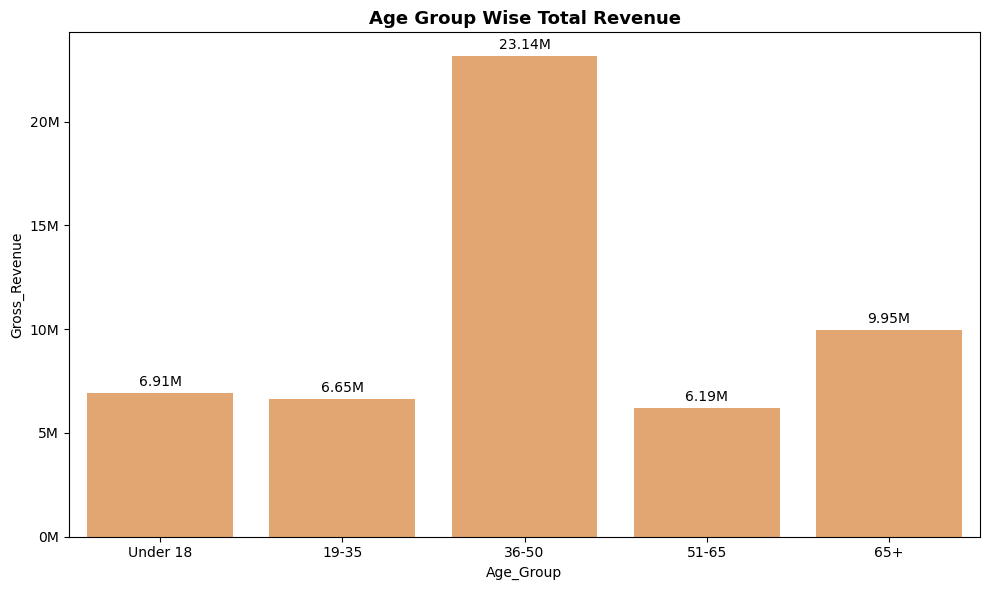

In [70]:
Age_Group_By_Revenue = df.groupby('Age_Group', as_index=False, observed= True)['Gross_Revenue'].sum().sort_values(by='Gross_Revenue', ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Age_Group', y='Gross_Revenue', data=Age_Group_By_Revenue, color='sandybrown')

for container in ax.containers:
    labels = [f'{bar.get_height()/1_000_000:.2f}M' for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, p: f'{x/1_000_000:.0f}M')
)
plt.title('Age Group Wise Total Revenue', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

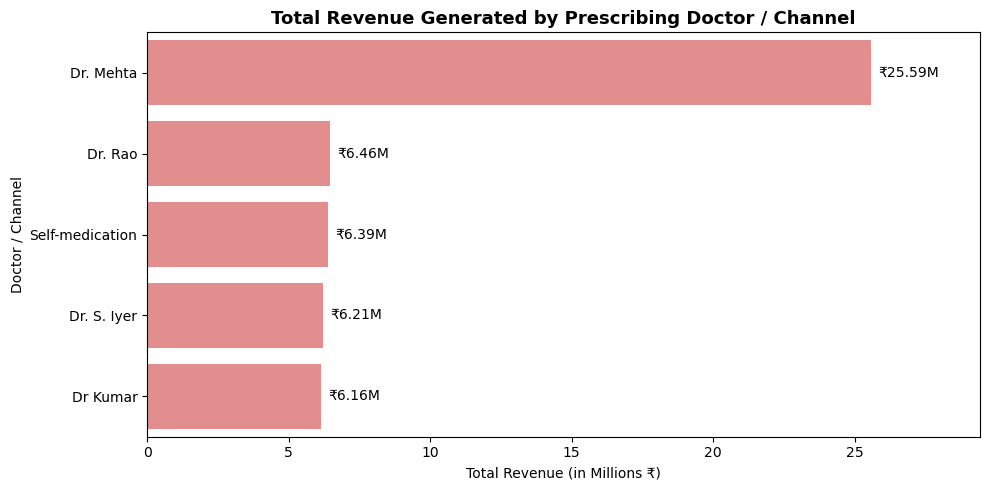

In [71]:
doc_summary = (df.groupby('Doctor_Name', as_index=False)
    .agg(Total_Amount=('Total_Amount', 'sum'),Prescription_Count=('Doctor_Name', 'count')).sort_values(by='Total_Amount', ascending=False))


doc_summary['Revenue_Millions'] = doc_summary['Total_Amount'] / 1e6

plt.figure(figsize=(10, 5))
ax = sns.barplot(x='Revenue_Millions', y='Doctor_Name', data=doc_summary, color='lightcoral')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.2fM', padding=5)

plt.xlim(0, doc_summary['Revenue_Millions'].max() * 1.15)
plt.title('Total Revenue Generated by Prescribing Doctor / Channel', fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (in Millions ₹)', fontsize=10)
plt.ylabel('Doctor / Channel', fontsize=10)
plt.tight_layout()
plt.show()

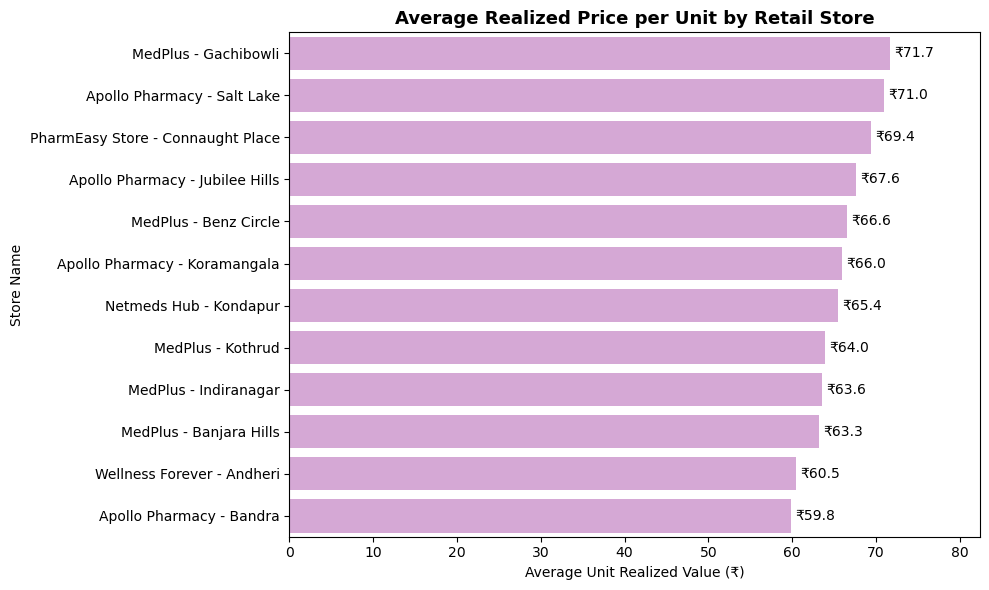

In [72]:
store_efficiency = df.groupby('Store_Name', as_index=False).agg({'Total_Amount': 'sum', 'Quantity': 'sum'})

store_efficiency['Avg_Unit_Price'] = store_efficiency['Total_Amount'] / store_efficiency['Quantity']
store_efficiency = store_efficiency.sort_values(by='Avg_Unit_Price', ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Avg_Unit_Price', y='Store_Name', data=store_efficiency, color='plum')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.1f', padding=3)

plt.xlim(0, store_efficiency['Avg_Unit_Price'].max() * 1.15)
plt.title('Average Realized Price per Unit by Retail Store', fontsize=13, fontweight='bold')
plt.xlabel('Average Unit Realized Value (₹)', fontsize=10)
plt.ylabel('Store Name', fontsize=10)
plt.tight_layout()
plt.show()

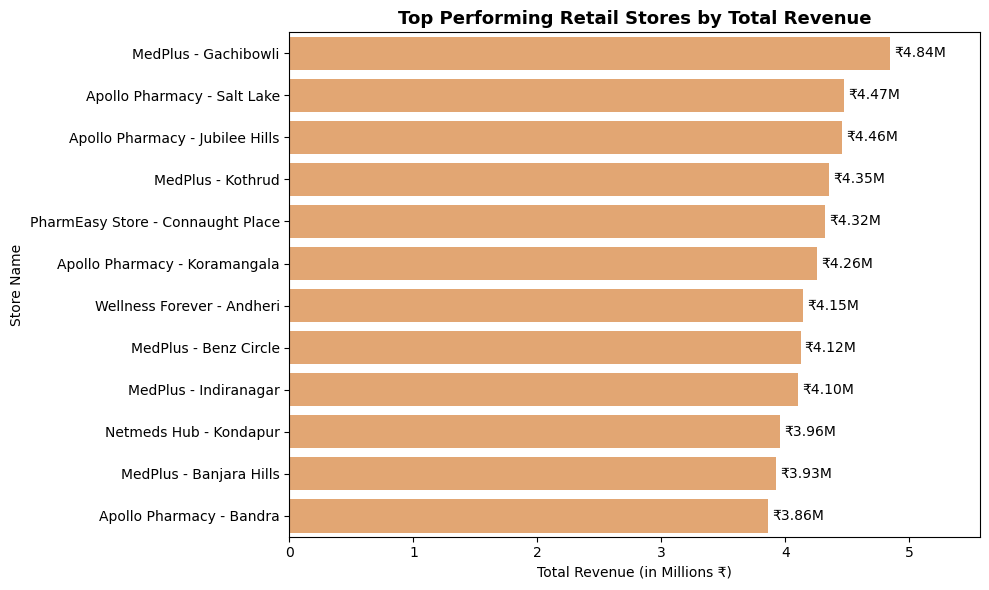

In [73]:
Store_Revenue = df.groupby('Store_Name', as_index=False)['Total_Amount'].sum().sort_values(by='Total_Amount', ascending=False)

Store_Revenue['Revenue_Millions'] = Store_Revenue['Total_Amount'] / 1e6

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Revenue_Millions', y='Store_Name', data=Store_Revenue, color='sandybrown')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.2fM', padding=3)

plt.xlim(0, Store_Revenue['Revenue_Millions'].max() * 1.15)

plt.title('Top Performing Retail Stores by Total Revenue', fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (in Millions ₹)', fontsize=10)
plt.ylabel('Store Name', fontsize=10)
plt.tight_layout()
plt.show()

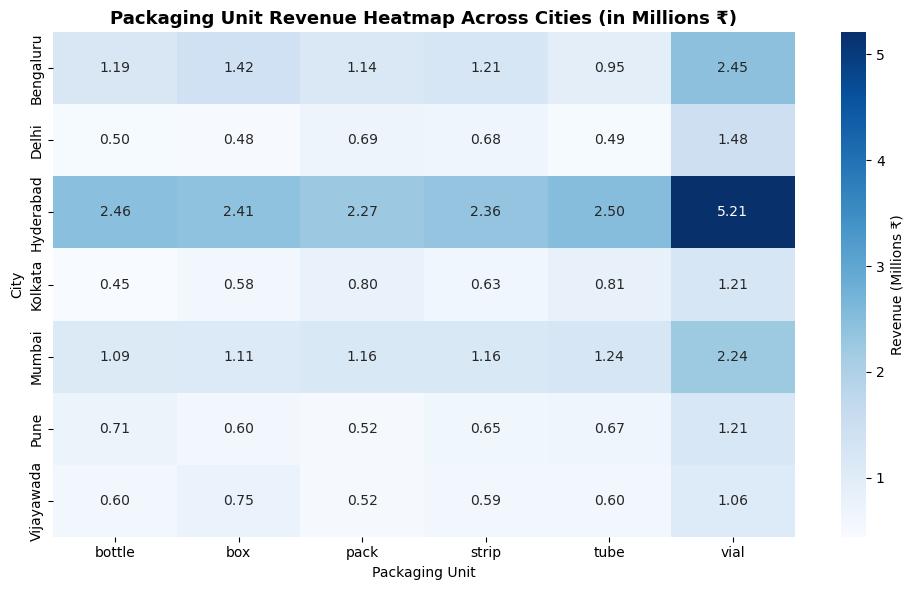

In [74]:
# Pivot data for heatmap representation
pivot_df = df.pivot_table(index='City', columns='Unit', values='Total_Amount', aggfunc='sum') / 1e6

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_df, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'Revenue (Millions ₹)'})
plt.title('Packaging Unit Revenue Heatmap Across Cities (in Millions ₹)', fontsize=13, fontweight='bold')
plt.xlabel('Packaging Unit')
plt.ylabel('City')
plt.tight_layout()
plt.show()

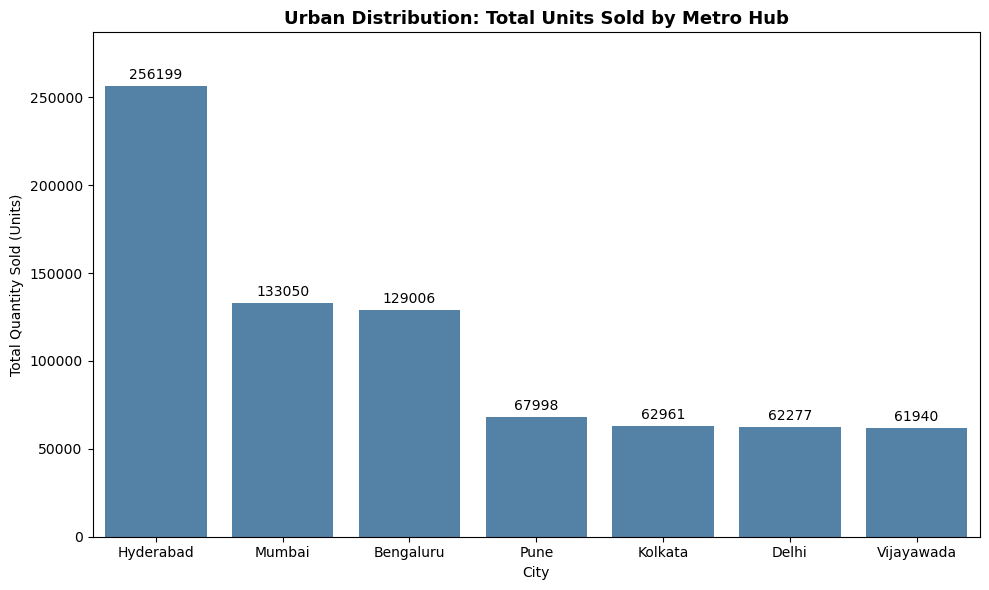

In [75]:
Quantity_by_City = df.groupby('City', as_index=False)['Quantity'].sum().sort_values(by='Quantity', ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='City', y='Quantity', data=Quantity_by_City, color='steelblue')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

max_qty = Quantity_by_City['Quantity'].max()
plt.ylim(0, max_qty * 1.12)

plt.title('Urban Distribution: Total Units Sold by Metro Hub', fontsize=13, fontweight='bold')
plt.xlabel('City', fontsize=10)
plt.ylabel('Total Quantity Sold (Units)', fontsize=10)
plt.tight_layout()
plt.show()

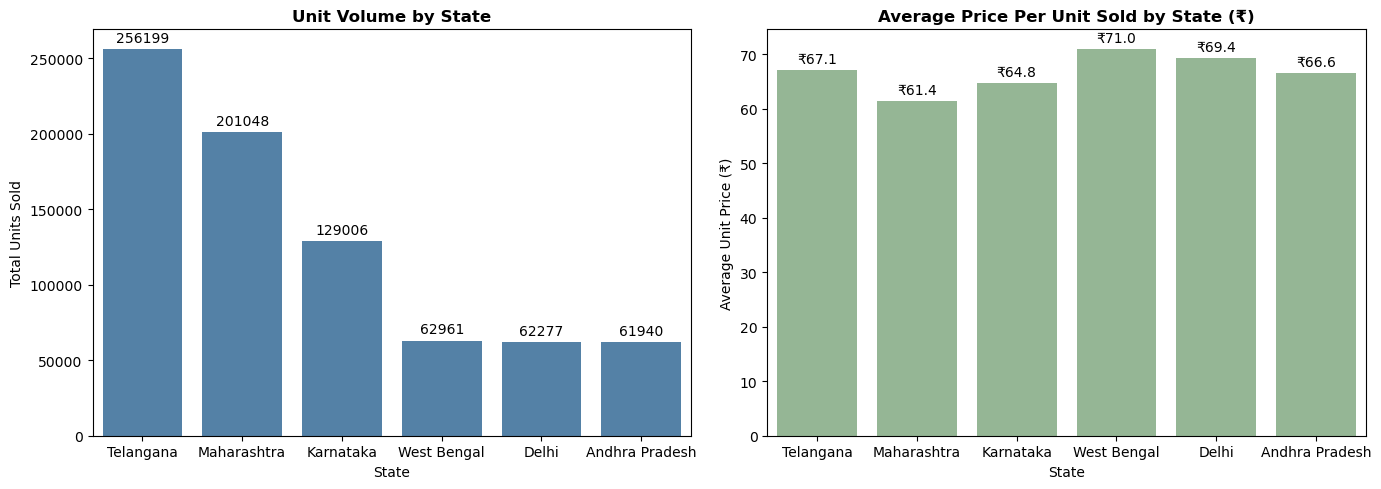

In [76]:
state_metrics = df.groupby('State', as_index=False).agg({'Total_Amount': 'sum','Quantity': 'sum'})

state_metrics['Avg_Price_Per_Unit'] = state_metrics['Total_Amount'] / state_metrics['Quantity']
state_metrics = state_metrics.sort_values(by='Total_Amount', ascending=False)
state_metrics['Revenue_M'] = state_metrics['Total_Amount'] / 1e6

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x='State', y='Quantity', data=state_metrics, ax=ax[0], color='steelblue')
ax[0].set_title('Unit Volume by State', fontweight='bold')
ax[0].set_ylabel('Total Units Sold')
for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.0f', padding=3)

sns.barplot(x='State', y='Avg_Price_Per_Unit', data=state_metrics, ax=ax[1], color='darkseagreen')
ax[1].set_title('Average Price Per Unit Sold by State (₹)', fontweight='bold')
ax[1].set_ylabel('Average Unit Price (₹)')
for container in ax[1].containers:
    ax[1].bar_label(container, fmt='₹%.1f', padding=3)

plt.tight_layout()
plt.show()

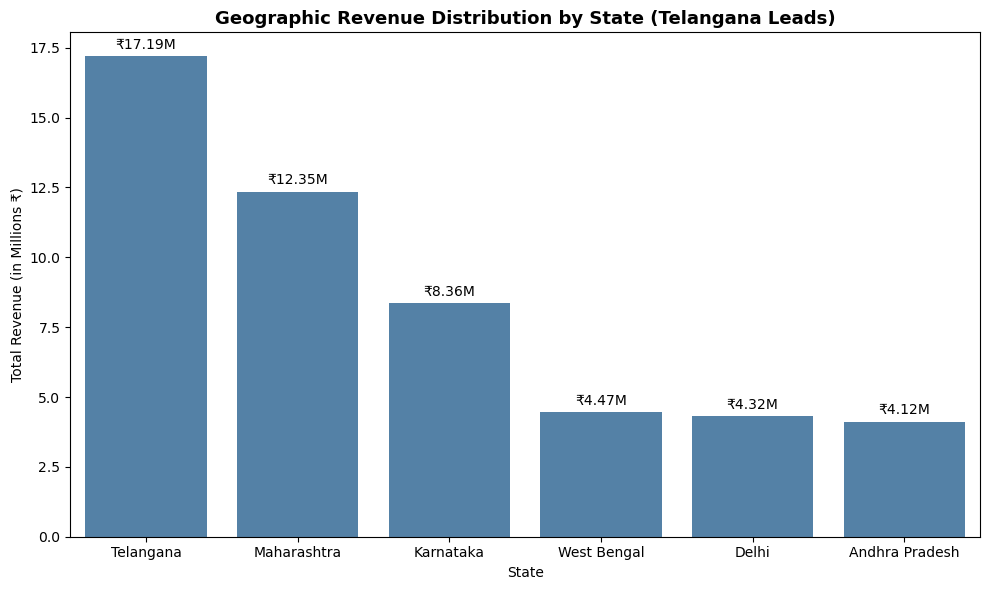

In [77]:
Total_Revenue_by_State = df.groupby('State', as_index=False)['Total_Amount'].sum().sort_values(by='Total_Amount', ascending=False)

Total_Revenue_by_State['Revenue_Millions'] = Total_Revenue_by_State['Total_Amount'] / 1e6

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='State', y='Revenue_Millions', data=Total_Revenue_by_State, color='steelblue')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.2fM', padding=3)

plt.title('Geographic Revenue Distribution by State (Telangana Leads)', fontsize=13, fontweight='bold')
plt.xlabel('State', fontsize=10)
plt.ylabel('Total Revenue (in Millions ₹)', fontsize=10)
plt.tight_layout()
plt.show()

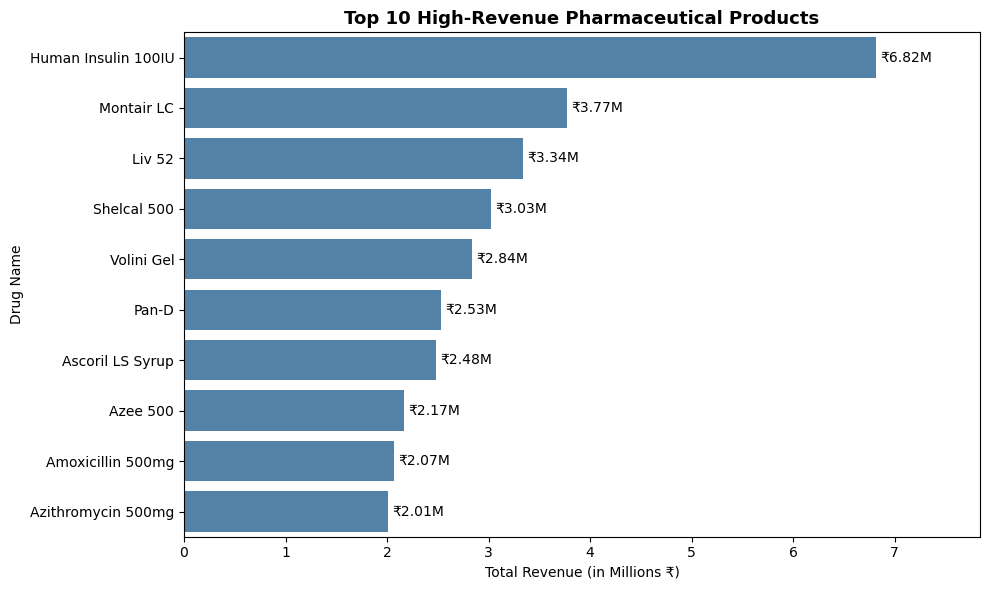

In [78]:
Revenue_by_Drug_Name = df.groupby('Drug_Name', as_index=False)['Total_Amount'].sum().sort_values(by='Total_Amount', ascending=False).head(10)

Revenue_by_Drug_Name['Revenue_Millions'] = Revenue_by_Drug_Name['Total_Amount'] / 1e6

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Revenue_Millions', y='Drug_Name', data=Revenue_by_Drug_Name, color='steelblue')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.2fM', padding=3)

max_rev = Revenue_by_Drug_Name['Revenue_Millions'].max()
plt.xlim(0, max_rev * 1.15)

plt.title('Top 10 High-Revenue Pharmaceutical Products', fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (in Millions ₹)', fontsize=10)
plt.ylabel('Drug Name', fontsize=10)
plt.tight_layout()
plt.show()

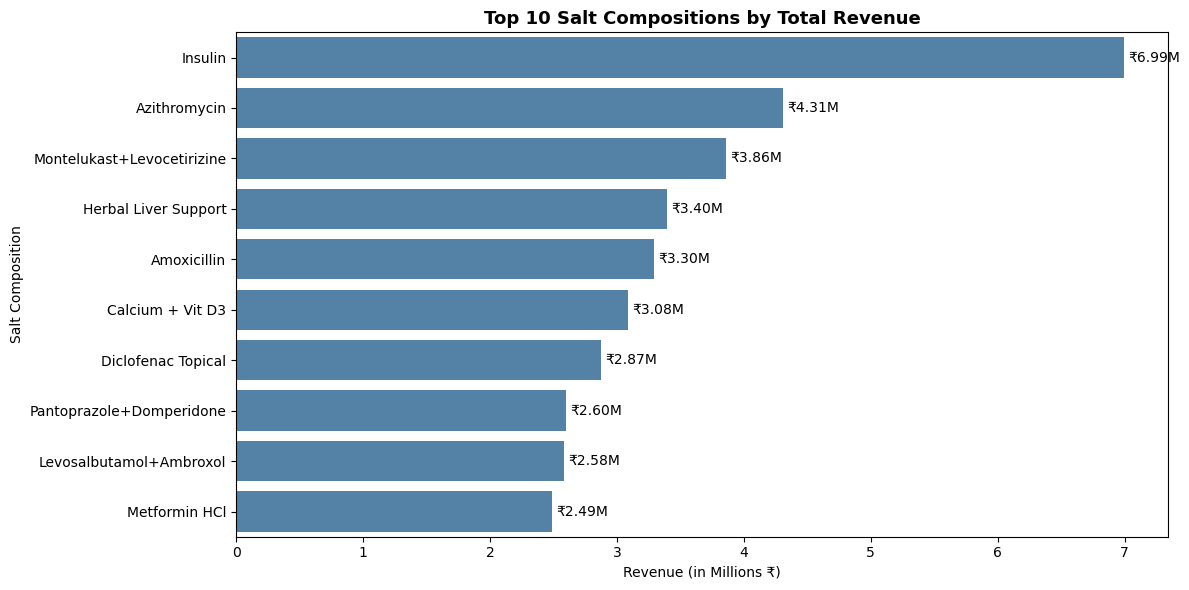

In [79]:
Top_10_Salt_Composition = df.groupby('Salt_Composition', as_index=False)['Total_Amount'].sum().sort_values(by='Total_Amount', ascending=False).head(10)

Top_10_Salt_Composition['Revenue_Millions'] = Top_10_Salt_Composition['Total_Amount'] / 1e6

plt.figure(figsize=(12, 6))
ax = sns.barplot(x='Revenue_Millions', y='Salt_Composition', data=Top_10_Salt_Composition, color='steelblue')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.2fM', padding=3)

plt.title('Top 10 Salt Compositions by Total Revenue', fontsize=13, fontweight='bold')
plt.xlabel('Revenue (in Millions ₹)', fontsize=10)
plt.ylabel('Salt Composition', fontsize=10)
plt.tight_layout()
plt.show()

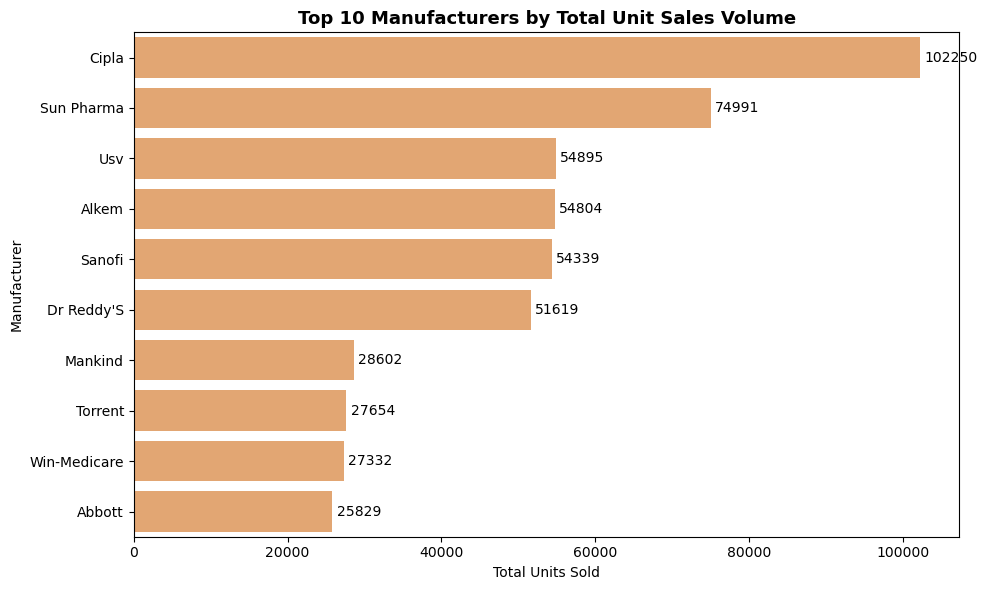

In [80]:
Manufacturer = df.groupby(['Manufacturer'], as_index=False)['Quantity'].sum().sort_values(by='Quantity', ascending=False).head(10)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Quantity', y='Manufacturer', data=Manufacturer, color='sandybrown')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Top 10 Manufacturers by Total Unit Sales Volume', fontsize=13, fontweight='bold')
plt.xlabel('Total Units Sold', fontsize=10)
plt.ylabel('Manufacturer', fontsize=10)
plt.tight_layout()
plt.show()

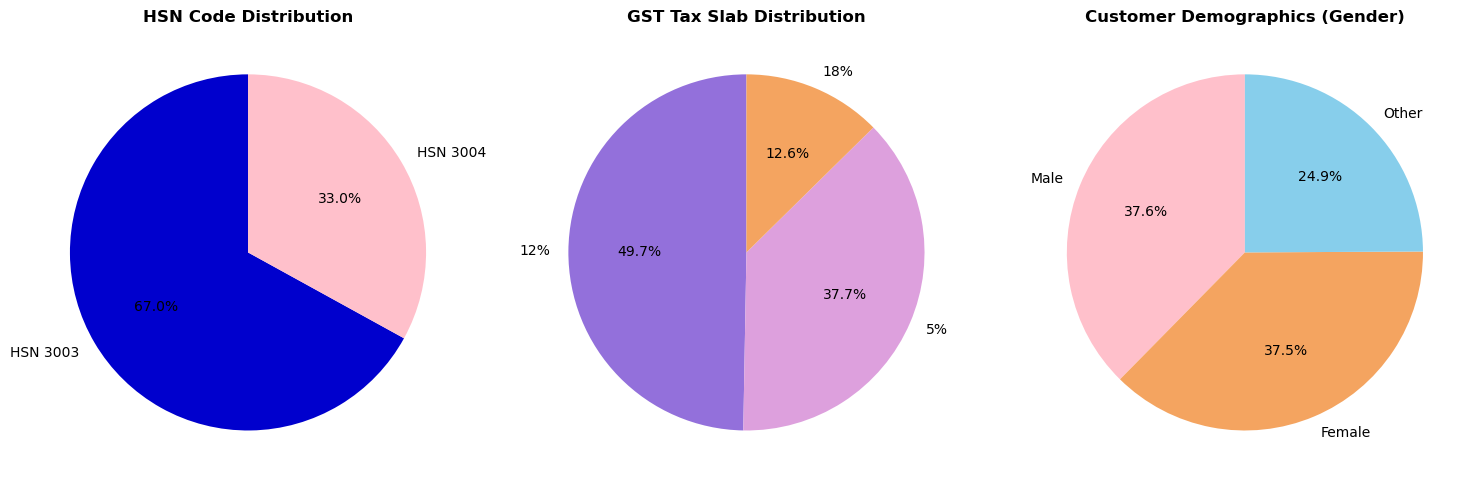

In [81]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

df['HSN_Code_Clean'] = df['HSN_Code'].astype(str).str.replace('.0', '', regex=False)
hsn_counts = df['HSN_Code_Clean'].value_counts()
ax[0].pie(
    hsn_counts.values, 
    labels=[f'HSN {x}' for x in hsn_counts.index], 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['mediumblue', 'pink']
)
ax[0].set_title('HSN Code Distribution', fontweight='bold')

df['GST_Clean'] = df['GST_Percent'].astype(str).str.replace('.0', '', regex=False) + '%'
gst_counts = df['GST_Clean'].value_counts()
ax[1].pie(
    gst_counts.values, 
    labels=gst_counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['mediumpurple', 'plum', 'sandybrown']
)
ax[1].set_title('GST Tax Slab Distribution', fontweight='bold')

# 3. Customer Gender Count
gender_counts = df['Customer_Gender'].value_counts()
ax[2].pie(
    gender_counts.values, 
    labels=gender_counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['pink', 'sandybrown', 'skyblue']
)
ax[2].set_title('Customer Demographics (Gender)', fontweight='bold')

plt.tight_layout()
plt.show()

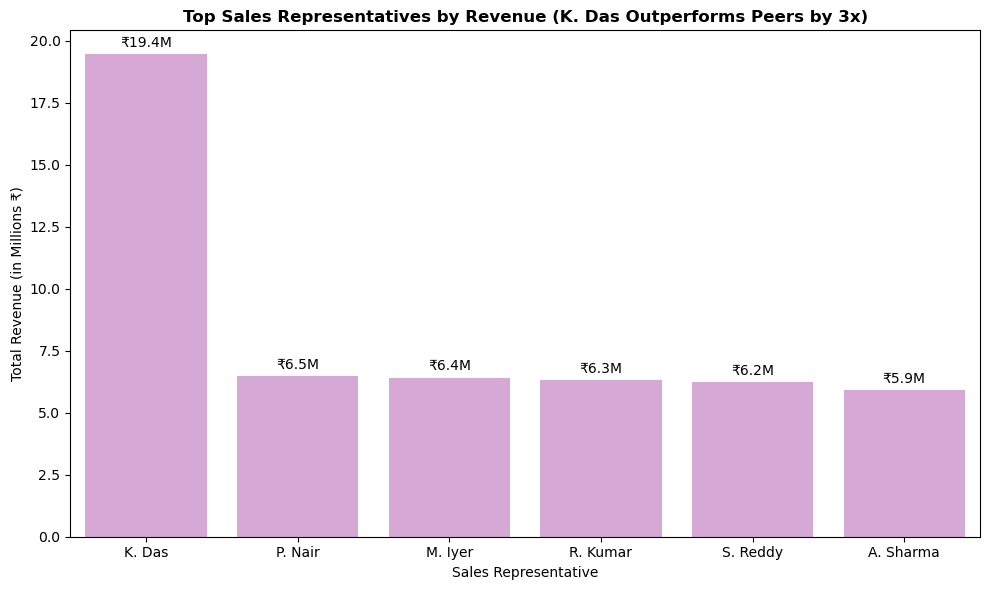

In [82]:
Total_Revenue_by_Sales_Rep = df.groupby('Sales_Rep', as_index=False)['Total_Amount'].sum().sort_values(by='Total_Amount', ascending=False).head(10)

Total_Revenue_by_Sales_Rep['Revenue_Millions'] = Total_Revenue_by_Sales_Rep['Total_Amount'] / 1e6

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Sales_Rep', y='Revenue_Millions', data=Total_Revenue_by_Sales_Rep, color='plum')

for container in ax.containers:
    ax.bar_label(container, fmt='₹%.1fM', padding=3)

plt.title('Top Sales Representatives by Revenue (K. Das Outperforms Peers by 3x)', fontsize=12, fontweight='bold')
plt.xlabel('Sales Representative', fontsize=10)
plt.ylabel('Total Revenue (in Millions ₹)', fontsize=10)
plt.tight_layout()
plt.show()

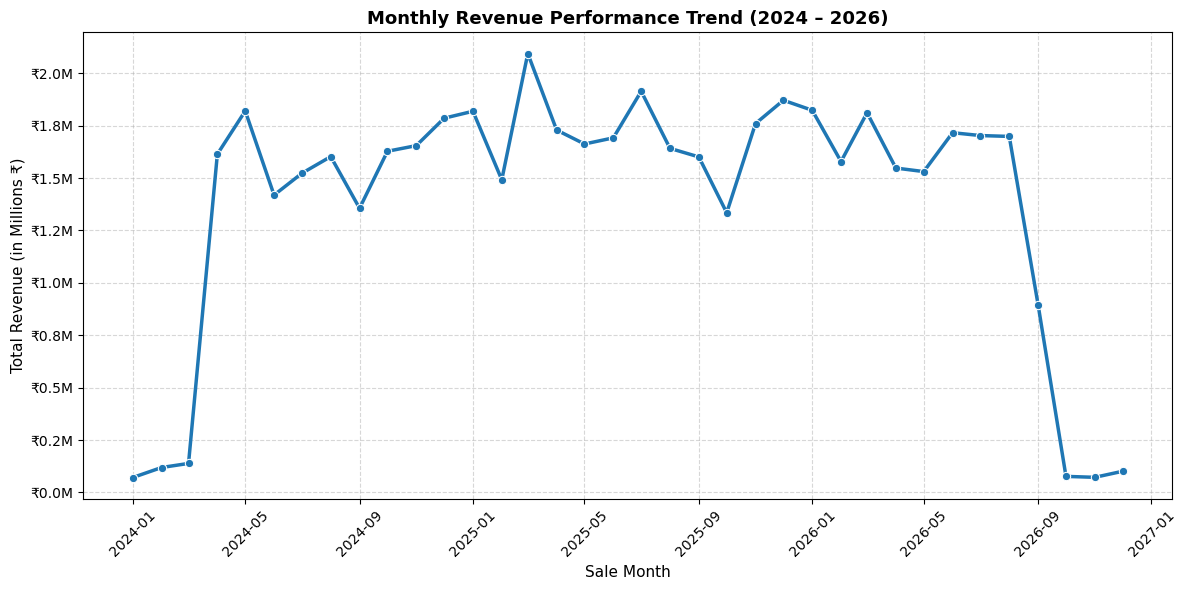

In [83]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], errors='coerce')

Monthly_Revenue = df.groupby(df['Sale_Date'].dt.to_period('M'))['Total_Amount'].sum().reset_index('Sale_Date')
Monthly_Revenue['Sale_Date'] = Monthly_Revenue['Sale_Date'].dt.to_timestamp()
Monthly_Revenue = Monthly_Revenue.sort_values('Sale_Date')

Monthly_Revenue['Revenue_Millions'] = Monthly_Revenue['Total_Amount'] / 1e6

plt.figure(figsize=(12, 6))
ax = sns.lineplot(x='Sale_Date', y='Revenue_Millions', data=Monthly_Revenue, marker='o', color='#1f77b4', linewidth=2.5)

plt.title('Monthly Revenue Performance Trend (2024 – 2026)', fontsize=13, fontweight='bold')
plt.xlabel('Sale Month', fontsize=11)
plt.ylabel('Total Revenue (in Millions ₹)', fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('₹%.1fM'))

plt.tight_layout()
plt.show()

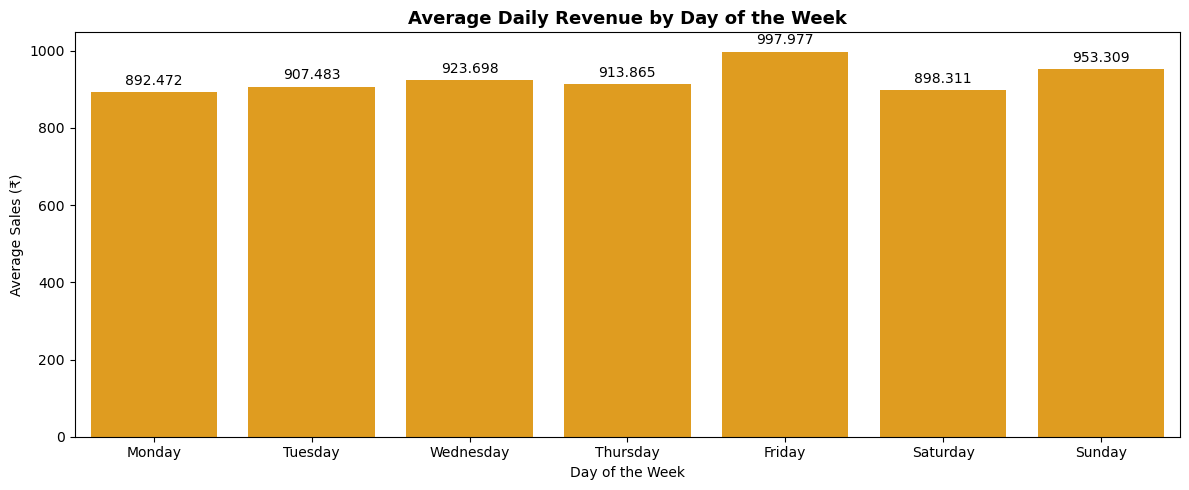

In [84]:
df['Day_of_Week'] = df['Sale_Date'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

daily_revenue = df.groupby('Day_of_Week', as_index=False)['Total_Amount'].mean()

plt.figure(figsize=(12, 5))
ax = sns.barplot(x='Day_of_Week', y='Total_Amount', data=daily_revenue, order=days_order, color='orange')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Average Daily Revenue by Day of the Week', fontsize=13, fontweight='bold')
plt.xlabel('Day of the Week')
plt.ylabel('Average Sales (₹)')
plt.tight_layout()
plt.show()

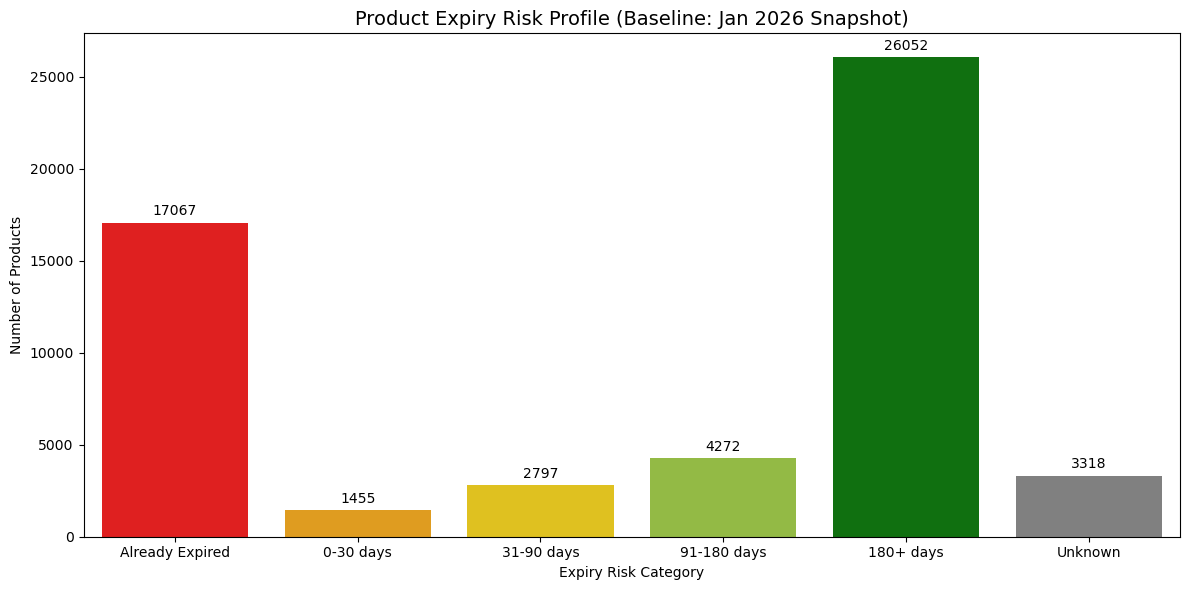

In [85]:
SNAPSHOT_DATE = pd.Timestamp('2026-01-01')

df['days_to_expirey'] = (df['Expiry_Date'] - SNAPSHOT_DATE).dt.days
def Expirey_bucket(days):
    if pd.isna(days):
        return 'Unknown'
    elif days <= 0:
        return 'Already Expired'
    elif days <= 30:
        return '0-30 days'
    elif days <= 90:
        return '31-90 days'
    elif days <= 180:
        return '91-180 days'
    else:
        return '180+ days'

df['Expiry_risk'] = df['days_to_expirey'].apply(Expirey_bucket)

order = ['Already Expired', '0-30 days', '31-90 days', '91-180 days', '180+ days', 'Unknown']
count_values = df['Expiry_risk'].value_counts().reindex(order)

plt.figure(figsize=(12,6))
ax = sns.barplot(x= count_values.index, y= count_values.values, hue= count_values.index, palette= ['red', 'orange', 'gold', 'yellowgreen',
'green', 'grey'], legend= False)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Product Expiry Risk Profile (Baseline: Jan 2026 Snapshot)', fontsize=14,)
plt.ylabel('Number of Products')
plt.xlabel('Expiry Risk Category')
plt.tight_layout()
plt.show()

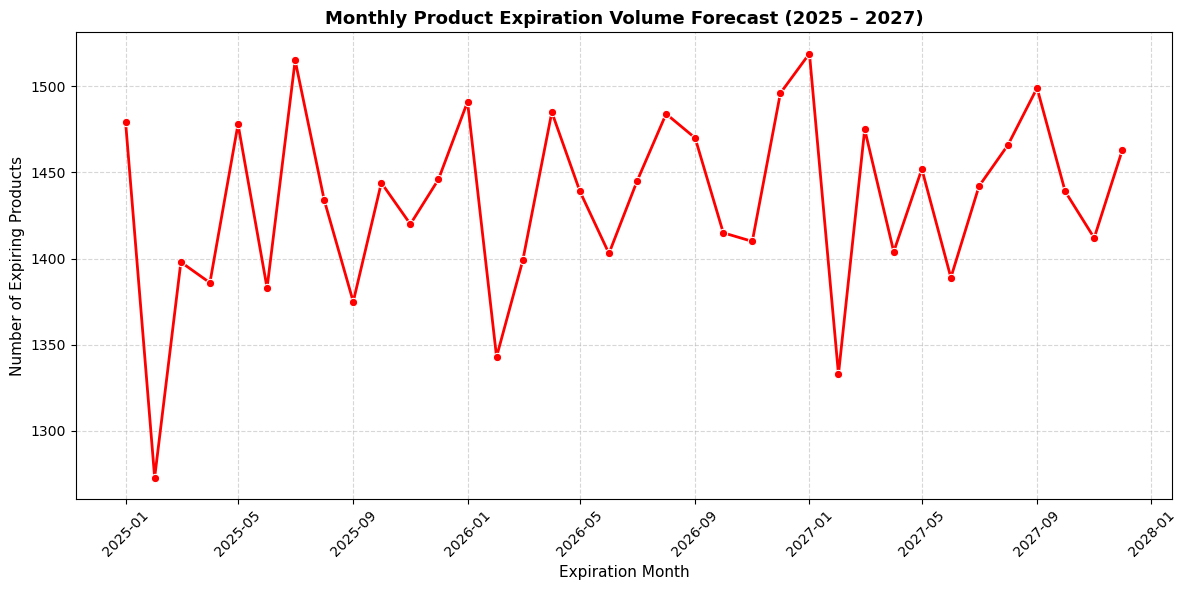

In [86]:
df['Expiry_Date'] = pd.to_datetime(df['Expiry_Date'], errors='coerce')

Monthly_Exp = df.groupby(df['Expiry_Date'].dt.to_period('M')).size().reset_index(name='Product_Count')

Monthly_Exp['Expiry_Date'] = Monthly_Exp['Expiry_Date'].dt.to_timestamp()
Monthly_Exp = Monthly_Exp.sort_values('Expiry_Date')

Monthly_Exp = Monthly_Exp[Monthly_Exp['Product_Count'] > 100]

plt.figure(figsize=(12, 6))
ax = sns.lineplot(x='Expiry_Date', y='Product_Count', data=Monthly_Exp, marker='o', color='red', linewidth=2)

plt.title('Monthly Product Expiration Volume Forecast (2025 – 2027)', fontsize=13, fontweight='bold')
plt.xlabel('Expiration Month', fontsize=11)
plt.ylabel('Number of Expiring Products', fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

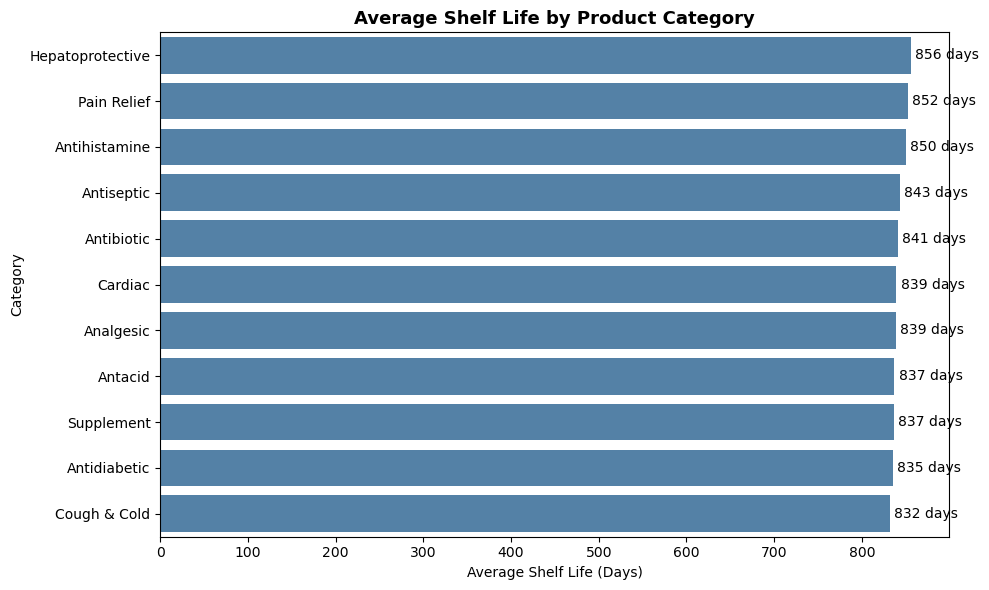

In [87]:
df['Expiry_Date'] = pd.to_datetime(df['Expiry_Date'], errors='coerce')
df['Mfg_Date'] = pd.to_datetime(df['Mfg_Date'], errors='coerce')

df['Shelf_Life_Days'] = (df['Expiry_Date'] - df['Mfg_Date']).dt.days

shelf_summary = (df.groupby('Category')['Shelf_Life_Days'].agg(['mean', 'median', 'min', 'max']) .reset_index())

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='mean', y='Category', data=shelf_summary.sort_values(by='mean', ascending=False), color='steelblue',)

for container in ax.containers:
  ax.bar_label(container, fmt='%.0f days', padding=3)

plt.title('Average Shelf Life by Product Category', fontsize=13, fontweight='bold')
plt.xlabel('Average Shelf Life (Days)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

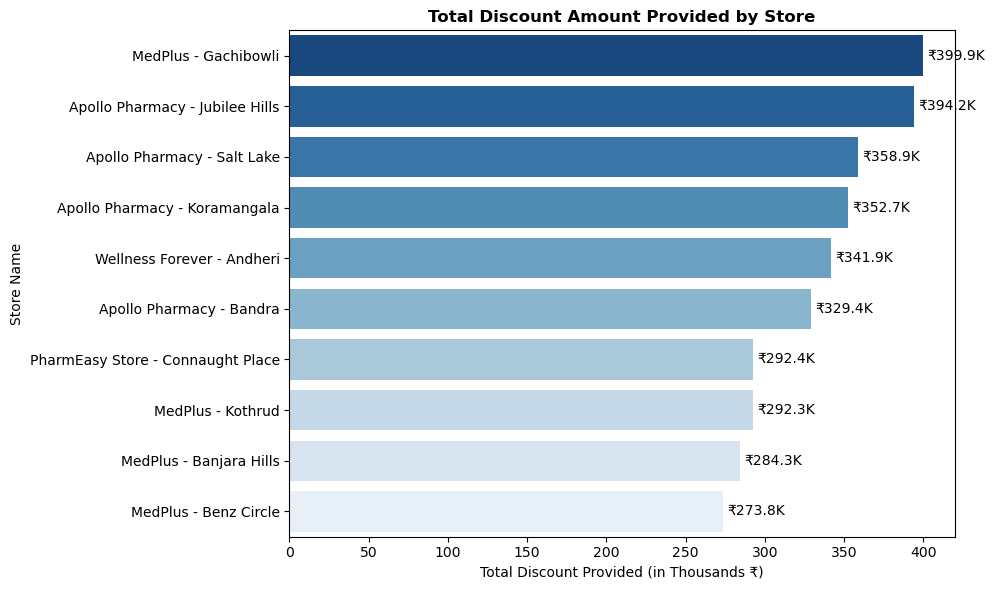

In [88]:
total_discount_given = (df.groupby('Store_Name', as_index=False)['Discount_Amount'].sum().sort_values(by='Discount_Amount', ascending=False))

total_discount_given['Discount_Thousands'] = (total_discount_given['Discount_Amount'] / 1000)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Discount_Thousands', y='Store_Name', data=total_discount_given.head(10), hue='Store_Name', palette='Blues_r', legend=False,)

for container in ax.containers:
  ax.bar_label(container, fmt='₹%.1fK', padding=3)

plt.title('Total Discount Amount Provided by Store', fontsize=12, fontweight='bold')
plt.xlabel('Total Discount Provided (in Thousands ₹)', fontsize=10)
plt.ylabel('Store Name', fontsize=10)
plt.tight_layout()
plt.show()

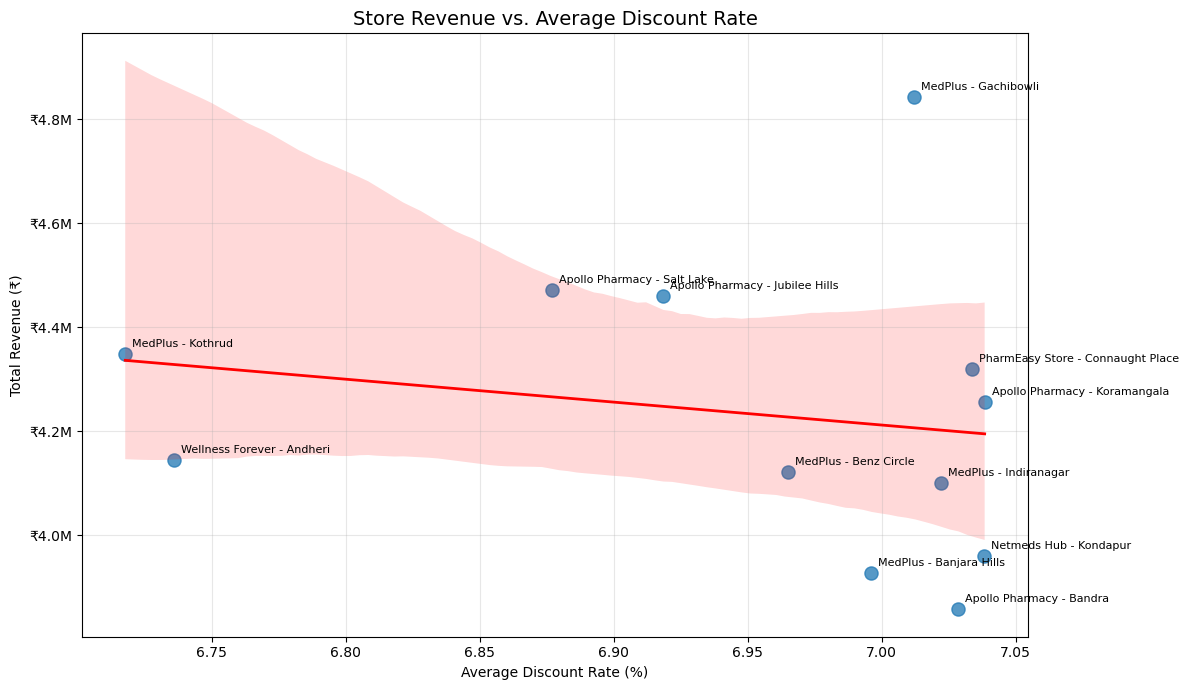

Correlation between discount rate and revenue: -0.183

Store Analysis:


,Store_ID,Store_Name,Total_Revenue,Avg_Discount_Rate,Transactions
2,STR03,MedPlus - Gachibowli,4843234.48,7.01,4652
10,STR11,Apollo Pharmacy - Salt Lake,4470862.48,6.88,4670
1,STR02,Apollo Pharmacy - Jubilee Hills,4460650.10,6.92,4499
8,STR09,MedPlus - Kothrud,4348973.64,6.72,4579
9,STR10,PharmEasy Store - Connaught Place,4319908.72,7.03,4568
4,STR05,Apollo Pharmacy - Koramangala,4256024.25,7.04,4658
6,STR07,Wellness Forever - Andheri,4145356.05,6.74,4666
11,STR12,MedPlus - Benz Circle,4122120.26,6.96,4499
5,STR06,MedPlus - Indiranagar,4100574.81,7.02,4542
3,STR04,Netmeds Hub - Kondapur,3960039.50,7.04,4538


In [89]:
df['Total_Amount'] = pd.to_numeric(df['Total_Amount'], errors='coerce')
df['Discount_Percent'] = pd.to_numeric(df['Discount_Percent'], errors='coerce')

store_analysis = (df.groupby(['Store_ID', 'Store_Name'], as_index=False).agg(Total_Revenue=('Total_Amount', 'sum'),
          Avg_Discount_Rate=('Discount_Percent', 'mean'), Transactions=('Total_Amount', 'count')))

store_analysis = store_analysis.dropna(subset=['Total_Revenue', 'Avg_Discount_Rate'])

plt.figure(figsize=(12, 7))
sns.regplot(data=store_analysis, x='Avg_Discount_Rate', y='Total_Revenue', scatter_kws={'s': 90, 'alpha': 0.75},
    line_kws={'color': 'red', 'linewidth': 2})

for _, row in store_analysis.iterrows():
    plt.annotate(str(row['Store_Name']), (row['Avg_Discount_Rate'], row['Total_Revenue']), xytext=(5, 5), textcoords='offset points', fontsize=8)

plt.title('Store Revenue vs. Average Discount Rate', fontsize=14)
plt.xlabel('Average Discount Rate (%)')
plt.ylabel('Total Revenue (₹)')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'₹{x / 1e6:.1f}M'))

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

correlation = store_analysis[['Avg_Discount_Rate', 'Total_Revenue']].corr().iloc[0, 1]

print(f"Correlation between discount rate and revenue: {correlation:.3f}")
print("\nStore Analysis:")
display(store_analysis.sort_values('Total_Revenue', ascending=False).round(2))